# Figure 1. BMI percentile ↔ percent-from-median mapping


datafile: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/shared/datafiles/datafile6.0_before_bfs_anthroqc_bmip_agediscrepancy_dmri_incl.txt
Rows used: 22,049
Weight category counts:
weight_cat
Underweight         630
Healthy Weight    14405
Overweight         3434
Obesity            3580


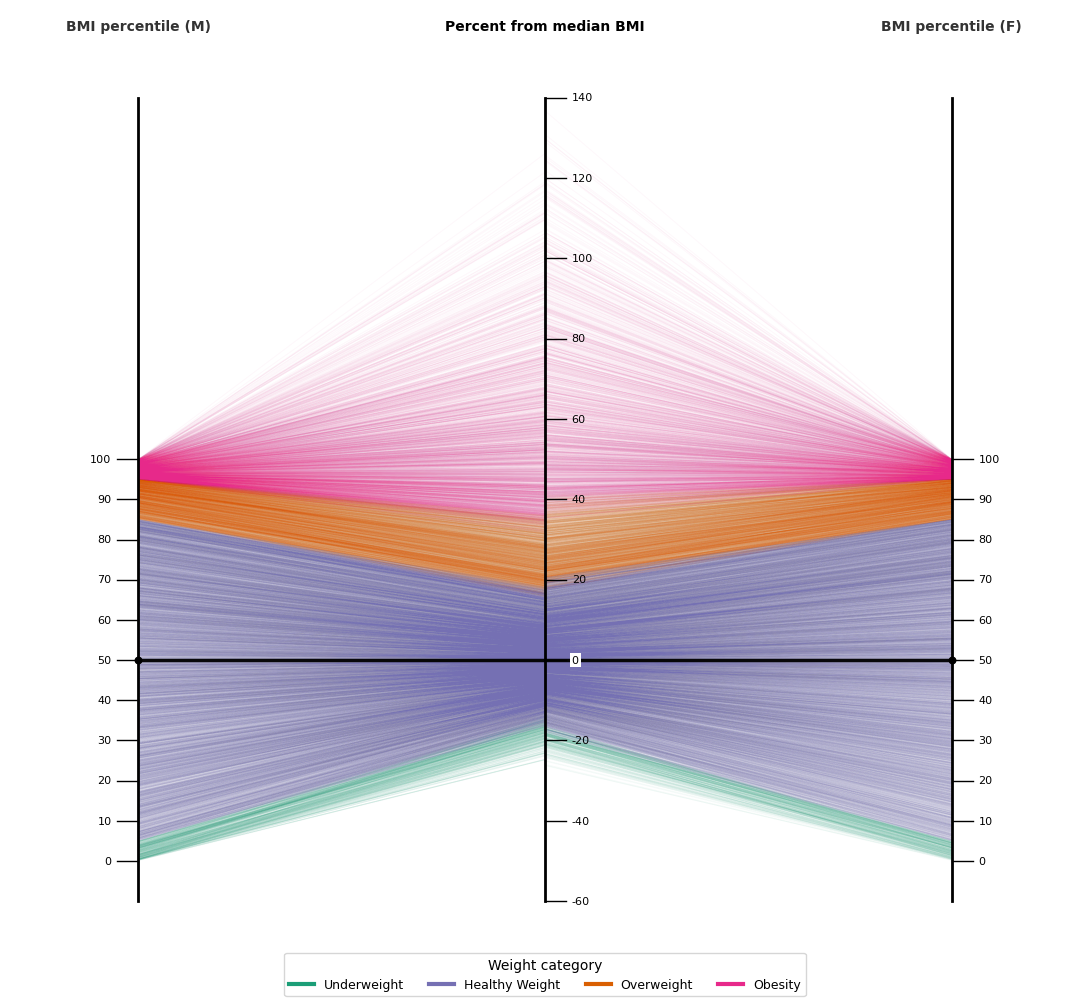

In [ ]:
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

ceph = Path(os.environ.get("BMI_IMAGING_CEPH_ROOT", "/space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis"))
SHARED_DATAFILES = Path(os.environ.get("BMI_IMAGING_SHARED_DATAFILES_DIR", ceph / "shared" / "datafiles"))
if not SHARED_DATAFILES.is_absolute():
    SHARED_DATAFILES = ceph / SHARED_DATAFILES

DATAFILE = Path(
    os.environ.get(
        "BMI_EXPLORE_DATAFILE",
        SHARED_DATAFILES / "datafile6.0_before_bfs_anthroqc_bmip_agediscrepancy_dmri_incl.txt",
    )
)
SAVE_PLOTS = os.environ.get("BMI_SAVE_PLOTS", "1").strip().lower() in ("1", "true", "yes", "on")
EXPORT_DIR = Path(
    os.environ.get("BMI_BMIP_EXPORT_DIR", str(ceph / "shared" / "bmip_metric_figures"))
).resolve()
EXPORT_DPI = int(os.environ.get("BMI_BMIP_EXPORT_DPI", "300"))


def save_fig(stem: str):
    if not SAVE_PLOTS:
        print("SAVE_PLOTS is off; not writing", stem)
        return None
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    safe = re.sub(r"[^A-Za-z0-9._-]+", "_", str(stem)).strip("_")
    out = EXPORT_DIR / f"{safe}.png"
    plt.savefig(out, dpi=EXPORT_DPI, bbox_inches="tight")
    print("Saved", out)
    return out


use_cols = ["bmip", "perc_median", "ab_g_stc__cohort_sex"]
df = pd.read_csv(DATAFILE, sep="\t", usecols=use_cols, low_memory=False)
sub = df.dropna().rename(columns={"ab_g_stc__cohort_sex": "sex"})
print(f"datafile: {DATAFILE}")
print(f"Rows used: {len(sub):,}")

WEIGHT_CAT_ORDER = [
    "Underweight",
    "Healthy Weight",
    "Overweight",
    "Obesity",
]
WEIGHT_CAT_COLORS = {
    "Underweight": "#1b9e77",
    "Healthy Weight": "#7570b3",
    "Overweight": "#d95f02",
    "Obesity": "#e7298a",
}


def weight_category_from_bmip(bmip: float) -> str:
    if bmip < 5:
        return "Underweight"
    if bmip < 85:
        return "Healthy Weight"
    if bmip < 95:
        return "Overweight"
    return "Obesity"


sub = sub.copy()
sub["weight_cat"] = sub["bmip"].map(weight_category_from_bmip)
print("Weight category counts:")
print(sub["weight_cat"].value_counts().reindex(WEIGHT_CAT_ORDER).to_string())

line_alpha = float(os.environ.get("BMI_YY_LINE_ALPHA", "0.04"))
line_width = float(os.environ.get("BMI_YY_LINE_WIDTH", "0.6"))

axis_bmip_min, axis_bmip_max = 0, 100
axis_pm_min, axis_pm_max = -60, 132
bmip_ticks = list(range(0, 101, 10))
pm_ticks = [-60, -40, -20, 0, 20, 40, 60, 80, 100, 120, 140]
bmip_ref = 50.0

x_m, x_pm, x_f = 0.12, 0.50, 0.88
pm_span = axis_pm_max - axis_pm_min


def y_from_pm(p):
    return (p - axis_pm_min) / pm_span


def y_from_bmip(b):
    return y_from_pm(0) + (b - bmip_ref) / pm_span


y_axis_bottom = float(y_from_pm(axis_pm_min))
_tick_ys = [y_from_bmip(t) for t in bmip_ticks] + [y_from_pm(t) for t in pm_ticks]
y_axis_top = max(_tick_ys)
y_span = y_axis_top - y_axis_bottom
y_ref = float(y_from_pm(0))
label_y = y_axis_top + 0.08 * y_span
y_lo = y_axis_bottom - 0.03
y_hi = label_y + 0.03 * y_span


def _draw_vertical_axis(ax, x, ticks, y_fn, tick_side, label, label_color="black"):
    ax.plot([x, x], [y_axis_bottom, y_axis_top], color="black", lw=2)
    for t in ticks:
        y = float(y_fn(t))
        if tick_side == "left":
            ax.plot([x - 0.02, x], [y, y], color="black", lw=1)
            ax.text(x - 0.025, y, f"{t:d}", ha="right", va="center", fontsize=8, zorder=15)
        else:
            ax.plot([x, x + 0.02], [y, y], color="black", lw=1)
            ax.text(x + 0.025, y, f"{t:d}", ha="left", va="center", fontsize=8, zorder=15)
    ax.text(
        x, label_y, label, ha="center", va="bottom", fontsize=10,
        fontweight="bold", color=label_color, zorder=30,
    )


fig, ax = plt.subplots(figsize=(11, 10.5))

m = sub[sub["sex"] == "M"]
f = sub[sub["sex"] == "F"]

for _, r in m.iterrows():
    color = WEIGHT_CAT_COLORS[r["weight_cat"]]
    ax.plot([x_m, x_pm], [y_from_bmip(r["bmip"]), y_from_pm(r["perc_median"])],
            color=color, alpha=line_alpha, lw=line_width)

for _, r in f.iterrows():
    color = WEIGHT_CAT_COLORS[r["weight_cat"]]
    ax.plot([x_pm, x_f], [y_from_pm(r["perc_median"]), y_from_bmip(r["bmip"])],
            color=color, alpha=line_alpha, lw=line_width)

ax.plot([x_m, x_f], [y_ref, y_ref], color="black", lw=2.5, alpha=0.95, zorder=10)
ax.scatter([x_m, x_f], [y_ref, y_ref], color="black", s=22, zorder=11)

_draw_vertical_axis(ax, x_m, bmip_ticks, y_from_bmip, "left", "BMI percentile (M)", "#333333")
_draw_vertical_axis(ax, x_f, bmip_ticks, y_from_bmip, "right", "BMI percentile (F)", "#333333")

pm_ticks_nozero = [t for t in pm_ticks if t != 0]
_draw_vertical_axis(ax, x_pm, pm_ticks_nozero, y_from_pm, "right", "Percent from median BMI", "black")
ax.plot([x_pm, x_pm + 0.02], [y_ref, y_ref], color="black", lw=1, zorder=20)
ax.text(
    x_pm + 0.025, y_ref, "0", ha="left", va="center", fontsize=8, zorder=30,
    bbox=dict(facecolor="white", edgecolor="none", pad=1.2, alpha=1.0),
)

legend_handles = [
    Line2D([0], [0], color=WEIGHT_CAT_COLORS[cat], lw=3, label=cat)
    for cat in WEIGHT_CAT_ORDER
]
fig.legend(
    handles=legend_handles,
    title="Weight category",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=4,
    frameon=True,
    fontsize=9,
)

ax.set_xlim(0.0, 1.0)
ax.set_ylim(y_lo, y_hi)
ax.axis("off")
fig.tight_layout(rect=[0, 0.08, 1, 0.98])
save_fig("fig1_two_axis_mapping_by_weight_category_legend_bottom_pm_neg60")
plt.show()
